# Allen–Cahn

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from project_runtime import select_device

from pinns import (
    SolutionModelNN,
    SpectralConfig,
    TrainingConfig,
    error_metrics,
    plot_heatmaps,
    plot_losses,
    plot_snapshots,
    predict_on_grid,
    sample_training_points,
    solve_spectral,
    train,
)

plt.rcParams.update({'font.size': 14})
torch.manual_seed(0)
device = select_device()
print(f'Compute device: {device}')
output_dir = Path.cwd() / 'outputs' / 'allen_cahn'
output_dir.mkdir(parents=True, exist_ok=True)

Compute device: cuda


In [2]:
x_bounds = (-1.0, 1.0)
t_bounds = (0.0, 1.0)
diffusion = 1e-4
reaction_rate = 5.0

def initial_condition(x):
    return x.square() * torch.cos(torch.pi * x)

def reaction(u):
    return reaction_rate * (u - u**3)

def equation(u, u_t, u_x, u_xx):
    return u_t - diffusion * u_xx - reaction(u)

In [3]:
spectral_config = SpectralConfig(n_space=2048, n_steps=100_000, save_every=100)
reference = solve_spectral(
    initial_condition=lambda x: initial_condition(torch.from_numpy(x)).numpy(),
    linear_symbol=lambda k: -diffusion * k**2,
    nonlinear_term=reaction,
    x_bounds=x_bounds,
    t_bounds=t_bounds,
    config=spectral_config,
)
np.savez_compressed(output_dir / 'reference.npz', t=reference.t, x=reference.x, u=reference.u)

Spectral steps: 10000/100000
Spectral steps: 20000/100000
Spectral steps: 30000/100000
Spectral steps: 40000/100000
Spectral steps: 50000/100000
Spectral steps: 60000/100000
Spectral steps: 70000/100000
Spectral steps: 80000/100000
Spectral steps: 90000/100000
Spectral steps: 100000/100000


In [4]:
points = sample_training_points(
    x_bounds, t_bounds, n_initial=50, n_boundary=50, n_interior=20_000, seed=0,
)
model = SolutionModelNN(in_size=2, hidden_size=100, out_size=1, hidden_layers=4)
training_config = TrainingConfig(
    epochs=2000,
    batch_size=312,
    learning_rate=1e-3,
    milestones=(150, 300, 450),
    initial_weight=10.0,
    device=str(device),
)

In [5]:
history = train(model, points, initial_condition, equation, training_config)
np.savez(output_dir / 'loss.npz', **history)
torch.save(model.state_dict(), output_dir / 'pinn.pt')

PINN training: model=cuda:0 (NVIDIA GeForce RTX 5060 Ti), interior=cuda:0, initial=cuda:0, boundaries=cuda:0/cuda:0, dtype=torch.float32; 65 updates/epoch, batch size 312
First backward pass: batch=cuda:0, loss=cuda:0, gradients=cuda:0, CUDA allocated=64.6 MiB


/home/avikgdas/amsc665_hw/project2/.venv/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 0: PDE=1.4285e-01, IC=1.3416e-01, BC=2.1160e-02, device=cuda:0, epoch_train=1.26s, train_total=1.26s; last 1 epochs=1.26s (47.4 epochs/min)
Epoch 100: PDE=4.4846e-01, IC=2.6631e-02, BC=7.0367e-03, device=cuda:0, epoch_train=0.42s, train_total=61.59s; last 100 epochs=60.32s (99.5 epochs/min)
Epoch 200: PDE=4.1696e-01, IC=1.9887e-02, BC=4.6455e-03, device=cuda:0, epoch_train=0.70s, train_total=119.28s; last 100 epochs=57.70s (104.0 epochs/min)
Epoch 300: PDE=4.1012e-01, IC=1.4873e-02, BC=4.5803e-03, device=cuda:0, epoch_train=0.51s, train_total=177.92s; last 100 epochs=58.64s (102.3 epochs/min)
Epoch 400: PDE=4.0024e-01, IC=1.4353e-02, BC=4.6190e-03, device=cuda:0, epoch_train=0.50s, train_total=238.00s; last 100 epochs=60.08s (99.9 epochs/min)
Epoch 500: PDE=3.8898e-01, IC=1.3422e-02, BC=2.4057e-03, device=cuda:0, epoch_train=0.64s, train_total=299.52s; last 100 epochs=61.52s (97.5 epochs/min)
Epoch 600: PDE=3.8654e-01, IC=1.2937e-02, BC=2.2492e-03, device=cuda:0, epoch_train=0.51

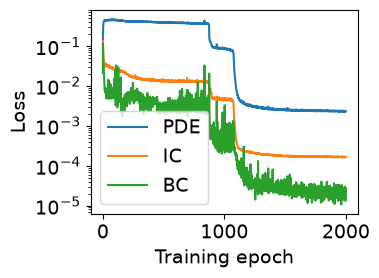

In [6]:
fig, ax = plot_losses(history)
fig.savefig(output_dir / 'loss.pdf')
plt.show()

In [7]:
predicted = predict_on_grid(model, reference.t, reference.x)
metrics = error_metrics(predicted, reference.u)
np.savez_compressed(
    output_dir / 'comparison.npz', t=reference.t, x=reference.x,
    u_spectral=reference.u, u_pinn=predicted, **metrics,
)
for name, value in metrics.items():
    print(f'{name} = {value:.4e}')

MAE = 2.0095e-01
RMSE = 3.7669e-01


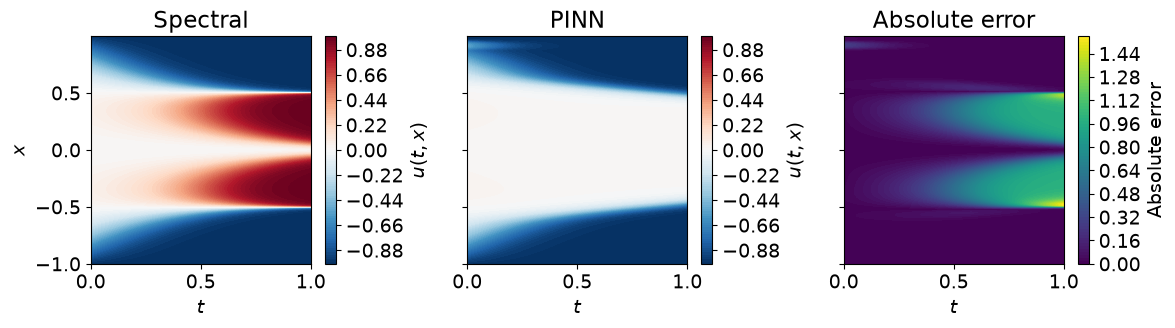

In [8]:
fig, axes = plot_heatmaps(reference.t, reference.x, reference.u, predicted)
fig.savefig(output_dir / 'heatmaps.pdf')
plt.show()

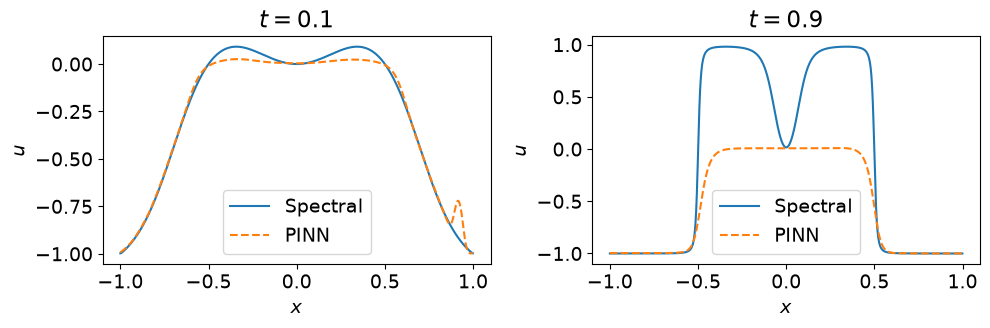

In [9]:
fig, axes = plot_snapshots(
    reference.t, reference.x, reference.u, predicted, times=(0.1, 0.9),
)
fig.savefig(output_dir / 'snapshots.pdf')
plt.show()